In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('jobs_dataset.csv')

print("First 5 rows of the dataset:")
display(df.head())

print("\nDataset Shape:", df.shape)

First 5 rows of the dataset:


,company,rating,location,positionName,description,salary,url,jobType/0,jobType/1,jobType/2,jobType/3,searchInput/country,searchInput/position,externalApplyLink
0,Google,4.3,"San Bruno, CA","Senior Data Scientist, Research, YouTube Search",Note: By applying to this position you will ha...,"$166,000 - $244,000 a year",https://www.indeed.com/viewjob?jk=3129ec5dde24...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://www.google.com/about/careers/applicati...
1,BAXTER,3.7,"Milwaukee, WI 53214",Senior AI Engineer - Data Scientist,This is where you save and sustain lives\n\nAt...,"$112,000 - $154,000 a year",https://www.indeed.com/viewjob?jk=19da1b85455c...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://jobs.baxter.com/en/job/-/-/152/8298788...
2,Meta,4.2,"Redmond, WA","Audio Software Engineer, Applied Scientist","Redmond, WA • + 2 more•Full Time\nMessenger\nM...",$70.67 an hour,https://www.indeed.com/viewjob?jk=0b0b432e2a51...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://www.metacareers.com/jobs/3101204833367...
3,Meta,4.2,"Bellevue, WA 98005","Software Engineer, Machine Learning","Bellevue, WA • Full Time\nMeta\nSoftware Engin...","$203,350 - $240,240 a year",https://www.indeed.com/viewjob?jk=08d2ef77c976...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://www.metacareers.com/jobs/1096352489054...
4,Lockheed Martin,4.0,"Shelton, CT 06484",AI / Machine Learning Research Engineer (early...,"Job ID: 694362BR\nDate posted: May. 22, 2025\n...",NaN,https://www.indeed.com/viewjob?jk=e9aad7dcc34e...,Full-time,NaN,NaN,NaN,US,Data Scientist,https://click.appcast.io/t/V35efAz0-l7FWwo6IKe...



Dataset Shape: (735, 14)


In [2]:
salary_col = 'salary' 

df['salary_num'] = df[salary_col].astype(str).str.replace(',', '').str.extract(r'(\d+\.?\d*)').astype(float)

df = df.dropna(subset=['salary_num'])

print("Dataset shape after cleaning salary:", df.shape)

Dataset shape after cleaning salary: (506, 15)


In [3]:
df['rating'] = df['rating'].fillna(df['rating'].median())

features = ["company", "rating", "location", "positionName"]
X = df[features]
y = df['salary_num']

print("Features and Target defined successfully!")

Features and Target defined successfully!


In [4]:
X = pd.get_dummies(X, columns=["company", "location", "positionName"], drop_first=True)

print("Features shape after One-Hot Encoding:", X.shape)

Features shape after One-Hot Encoding: (506, 889)


In [5]:
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(random_state=42)

model.fit(X, y)

print("DecisionTreeRegressor model trained successfully!")

DecisionTreeRegressor model trained successfully!


In [6]:
y_pred = model.predict(X)

comparison_df = pd.DataFrame({
    'Actual Salary': y.values[:10], 
    'Predicted Salary': y_pred[:10]
})

print("Comparison between Actual and Predicted Salaries:")
display(comparison_df)

Comparison between Actual and Predicted Salaries:


,Actual Salary,Predicted Salary
0,166000.00,166000.00
1,112000.00,112000.00
2,70.67,70.67
3,203350.00,203350.00
4,197000.00,197000.00
5,128250.00,128250.00
6,293755.64,293755.64
7,70000.00,70000.00
8,138257.60,138257.60
9,85.10,85.10


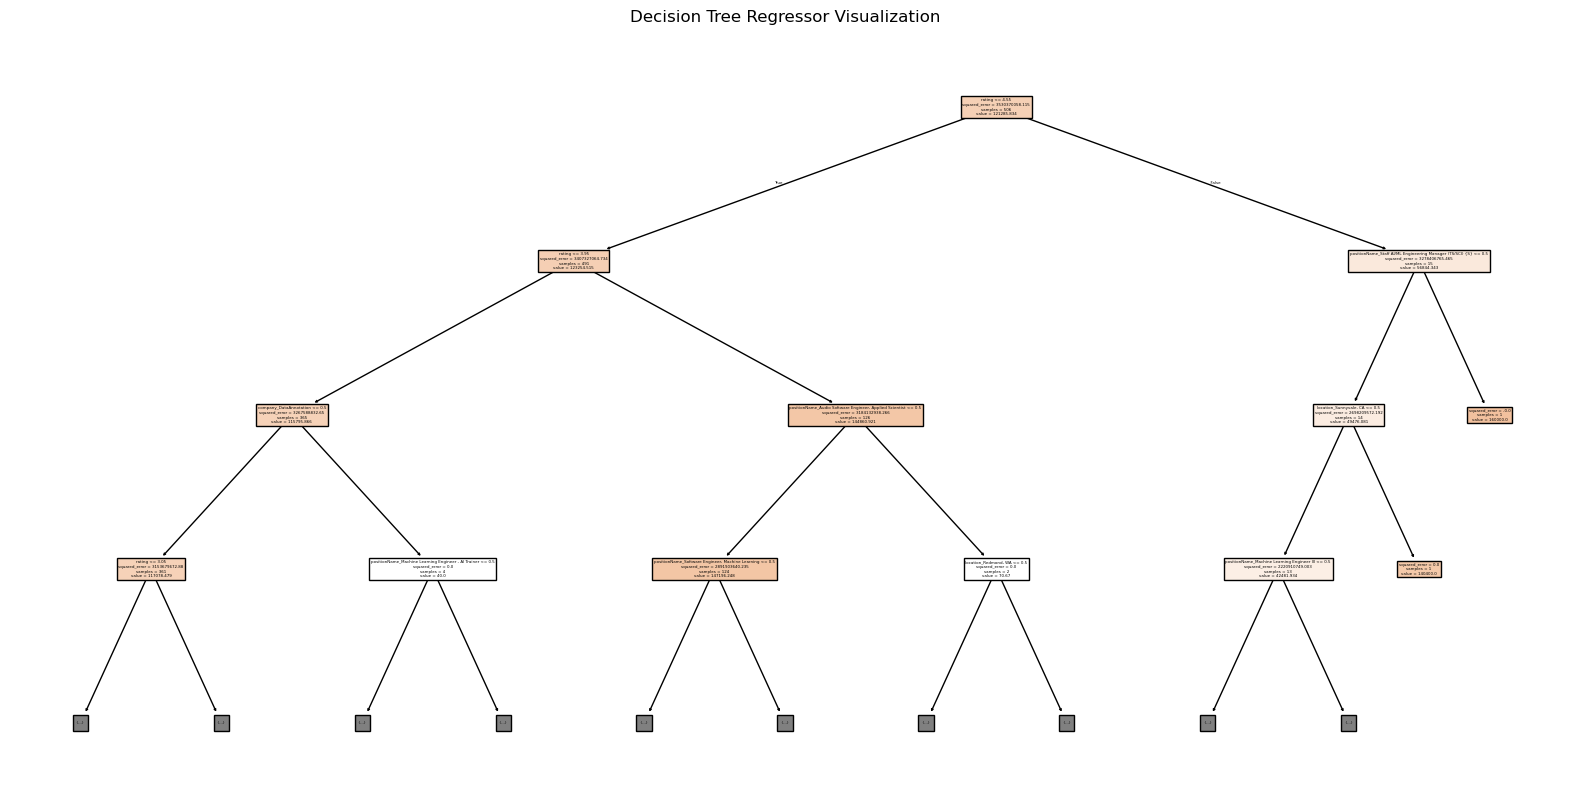

In [7]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))
plot_tree(model, filled=True, feature_names=X.columns.tolist(), max_depth=3)
plt.title("Decision Tree Regressor Visualization")
plt.show()